# Swing Metrics — Combined MLB Assessment
Analyzes `swing_path_tilt`, `attack_angle`, `attack_direction`, and
`intercept_ball_minus_batter_pos_y_inches` (contact depth) together.

Focus: what drives high Pull Air rates?

**Sections**
1. Imports & config
2. Load data & derive outcomes
3. Distribution analysis
4. Reliability (Cronbach's α, up to 40 BBE)
5. Stickiness (2024→2025 YoY Spearman ρ)
6. Pairwise correlations between metrics
7. Outcome correlations (all four metrics)
8. Ridge regression with interactions
9. Pull Air% deep dive — partial effects


## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MIN_BBE  = 25   # leaderboard / outcome correlation threshold
N_ITEMS  =  5   # Cronbach's alpha chunk splits
N_SPLITS =  50  # bootstrap iterations (fast)
REL_MAX_BBE = 40  # reliability curve stops here

METRICS = {
    "swing_path_tilt":                        "Swing Path Tilt",
    "attack_angle":                            "Attack Angle",
    "attack_direction_norm":                   "Attack Direction (norm)",
    "intercept_ball_minus_batter_pos_y_inches":"Contact Depth",
}
METRIC_COLS   = list(METRICS.keys())
METRIC_LABELS = list(METRICS.values())

COLORS = ["#1565C0", "#E53935", "#2E7D32", "#F57F17"]

print("Imports OK")


Imports OK


## 2. Load Data & Derive Outcomes

In [17]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))

def filter_contact(df):
    mask = (
        df["launch_speed"].notna() &
        df["launch_angle"].notna() &
        df["stand"].notna() &
        df["hc_x"].notna()
    )
    return df[mask].copy().reset_index(drop=True)

ip_2024 = filter_contact(raw_2024)
ip_2025 = filter_contact(raw_2025)
ip_all  = pd.concat([ip_2024, ip_2025], ignore_index=True)

print(f"2024: {len(ip_2024):,}  ({ip_2024['batter'].nunique()} batters)")
print(f"2025: {len(ip_2025):,}  ({ip_2025['batter'].nunique()} batters)")
print(f"Combined: {len(ip_all):,}")

# ── Metric availability
print("\nMetric non-null rates:")
for col, label in METRICS.items():
    rate = ip_all[col].notna().mean() if col in ip_all.columns else 0.0
    print(f"  {label:<30s}  {rate:.1%}")

# ── Outcome columns
for df in [ip_2024, ip_2025, ip_all]:
    df["sweet_spot"]  = df["launch_angle"].between(8,  32).astype(int)
    df["barrel_adj"]  = (
        (df["launch_speed"] >= 98) & df["launch_angle"].between(26, 30)
    ).astype(int)
    df["ground_ball"] = (df["launch_angle"] <  10).astype(int)
    df["fly_ball"]    = (df["launch_angle"] >  25).astype(int)
    # Spray angle per Statcast formula
    df["spray_angle"]      = np.degrees(
        np.arctan((df["hc_x"] - 125.42) / (198.27 - df["hc_y"]))
    )
    df["spray_angle_norm"] = np.where(
        df["stand"] == "R", df["spray_angle"], -df["spray_angle"]
    )
    df["pull_flag"]        = (df["spray_angle_norm"] > 0).astype(int)
    df["pull_air"]         = (
        (df["spray_angle_norm"] > 0) & (df["launch_angle"] > 10)
    ).astype(int)
    # Attack direction normalised: pull = positive for both sides
    if "attack_direction" in df.columns:
        df["attack_direction_norm"] = np.where(
            df["stand"] == "R",
            df["attack_direction"],
            -df["attack_direction"],
        )
    df["air_ball"] = (df["launch_angle"] >= 10).astype(int)
    df["pull_given_air"] = np.where(
        df["air_ball"] == 1,
        df["pull_flag"],
        np.nan,   # exclude grounders from this metric
    )

OUTCOME_COLS = {
    "Sweet Spot%":  "sweet_spot",
    "Barrel%":      "barrel_adj",
    "Ground Ball%": "ground_ball",
    "Fly Ball%":    "fly_ball",
    "Pull%":        "pull_flag",
    "Pull Air%":    "pull_air",
    "Mean LA":      "launch_angle",
    "Mean EV":      "launch_speed",
}

print("\nOutcome columns derived.")


2024: 125,749  (890 batters)
2025: 126,961  (972 batters)
Combined: 252,710

Metric non-null rates:
  Swing Path Tilt                 91.7%
  Attack Angle                    91.7%
  Attack Direction (norm)         0.0%
  Contact Depth                   91.7%

Outcome columns derived.


## 3. Distribution Analysis

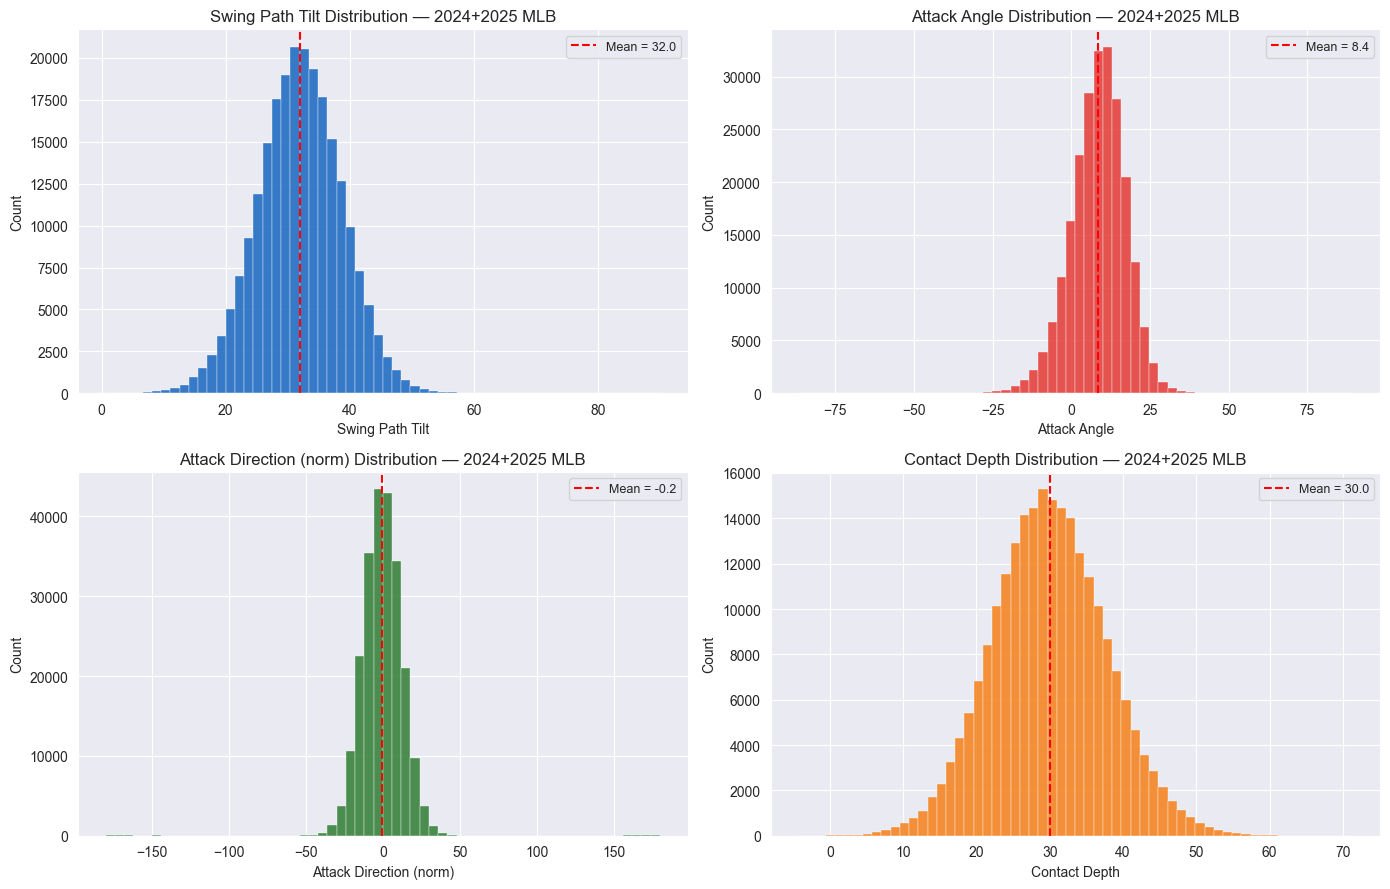


Swing Path Tilt:
  Overall  mean=32.00  std=6.97  range=[0.7, 89.9]
  RHH     mean=31.54  std=6.98
  LHH     mean=32.60  std=6.91

Attack Angle:
  Overall  mean=8.41  std=9.38  range=[-86.8, 89.3]
  RHH     mean=8.39  std=9.32
  LHH     mean=8.44  std=9.45

Attack Direction (norm):
  Overall  mean=-0.22  std=14.52  range=[-179.8, 179.8]
  RHH     mean=0.00  std=14.74
  LHH     mean=-0.51  std=14.21

Contact Depth:
  Overall  mean=29.99  std=7.81  range=[-4.3, 71.3]
  RHH     mean=30.13  std=7.82
  LHH     mean=29.82  std=7.80


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, (col, label), color in zip(axes, METRICS.items(), COLORS):
    data = ip_all[col].dropna()
    if data.empty:
        ax.set_title(f"{label} — no data")
        continue
    ax.hist(data, bins=60, color=color, alpha=0.85,
            edgecolor="white", linewidth=0.3)
    ax.axvline(data.mean(), color="red", linewidth=1.5, linestyle="--",
               label=f"Mean = {data.mean():.1f}")
    ax.set_xlabel(f"{label}")
    ax.set_ylabel("Count")
    ax.set_title(f"{label} Distribution — 2024+2025 MLB")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# ── Summary stats + handedness split
for col, label in METRICS.items():
    if col not in ip_all.columns:
        continue
    print(f"\n{label}:")
    print(f"  Overall  mean={ip_all[col].mean():.2f}  std={ip_all[col].std():.2f}  "
          f"range=[{ip_all[col].min():.1f}, {ip_all[col].max():.1f}]")
    for side in ["R", "L"]:
        sub = ip_all[ip_all["stand"] == side][col].dropna()
        print(f"  {side}HH     mean={sub.mean():.2f}  std={sub.std():.2f}")


## 4. Reliability (Cronbach's α — up to 40 BBE)

In [4]:
def cronbach_alpha(items_df):
    k         = items_df.shape[1]
    item_var  = items_df.var(axis=0, ddof=1).sum()
    total_var = items_df.sum(axis=1).var(ddof=1)
    return np.nan if total_var == 0 else (k / (k - 1)) * (1 - item_var / total_var)

def reliability_at_threshold(df, col, thresh):
    eligible = [
        bid for bid, grp in df.groupby("batter")
        if grp[col].notna().sum() >= thresh * N_ITEMS
    ]
    if len(eligible) < 15:
        return None
    sub    = df[df["batter"].isin(eligible)]
    alphas = []
    for _ in range(N_SPLITS):
        rows = []
        for bid, grp in sub.groupby("batter"):
            valid    = grp[grp[col].notna()].sample(frac=1)
            chunk_means = [valid.iloc[i::N_ITEMS][col].mean()
                           for i in range(N_ITEMS)]
            if not any(np.isnan(chunk_means)):
                rows.append(chunk_means)
        items = pd.DataFrame(rows).dropna()
        if len(items) < 10:
            continue
        alphas.append(cronbach_alpha(items))
    return {
        "thresh":     thresh,
        "n_batters":  len(eligible),
        "alpha_mean": float(np.nanmean(alphas)),
        "alpha_std":  float(np.nanstd(alphas)),
    } if alphas else None

thresholds = list(range(5, REL_MAX_BBE + 1, 5))
rel_results = {}

for col, label in METRICS.items():
    if col not in ip_2024.columns or ip_2024[col].notna().sum() == 0:
        print(f"  {label}: skipped (no data)")
        continue
    print(f"  {label} …", end=" ")
    results = [r for t in thresholds
               if (r := reliability_at_threshold(ip_2024, col, t))]
    rel_results[col] = pd.DataFrame(results)
    if results:
        print(f"done  (α={results[-1]['alpha_mean']:.3f} at BBE={results[-1]['thresh']})")
    else:
        print("no results")

print("Done.")


  Swing Path Tilt … 

KeyboardInterrupt: 

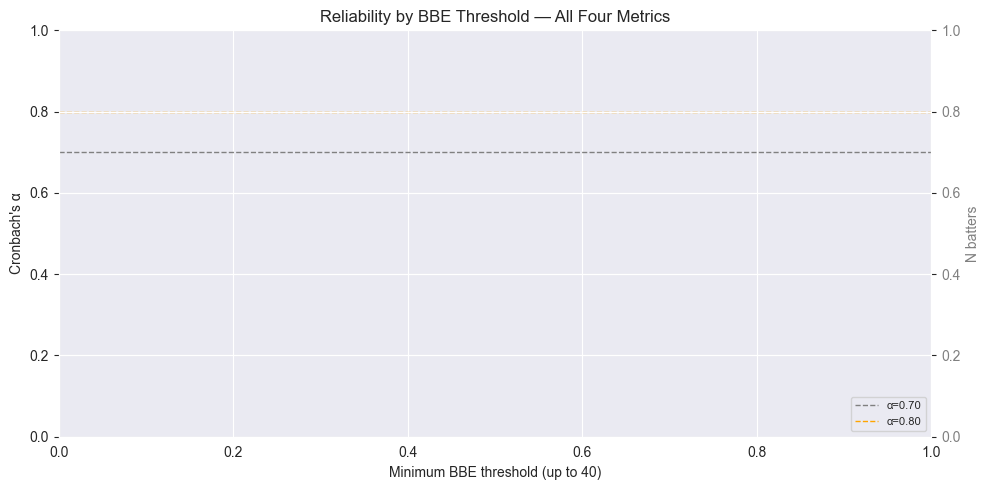


Metric                            α=0.70 at BBE    α=0.80 at BBE
-----------------------------------------------------------------


In [6]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

for (col, label), color in zip(METRICS.items(), COLORS):
    if col not in rel_results or rel_results[col].empty:
        continue
    rel = rel_results[col]
    ax1.plot(rel["thresh"], rel["alpha_mean"], color=color,
             linewidth=2, label=label)
    ax1.fill_between(rel["thresh"],
                     rel["alpha_mean"] - rel["alpha_std"],
                     rel["alpha_mean"] + rel["alpha_std"],
                     alpha=0.1, color=color)
    # n_batters bar for first metric only
    if col == METRIC_COLS[0]:
        ax2.bar(rel["thresh"], rel["n_batters"],
                alpha=0.1, color="gray", width=4)

ax1.axhline(0.70, color="gray",   linewidth=1, linestyle="--", label="α=0.70")
ax1.axhline(0.80, color="orange", linewidth=1, linestyle="--", label="α=0.80")
ax1.set_xlabel(f"Minimum BBE threshold (up to {REL_MAX_BBE})")
ax1.set_ylabel("Cronbach's α")
ax1.set_title("Reliability by BBE Threshold — All Four Metrics")
ax1.legend(fontsize=8, loc="lower right")
ax1.set_ylim(0, 1)
ax2.set_ylabel("N batters", color="gray")
ax2.tick_params(axis="y", labelcolor="gray")

plt.tight_layout()
plt.show()

print(f"\n{'Metric':<30}  {'α=0.70 at BBE':>15}  {'α=0.80 at BBE':>15}")
print("-" * 65)
for col, label in METRICS.items():
    if col not in rel_results or rel_results[col].empty:
        continue
    rel = rel_results[col]
    for target in [0.70, 0.80]:
        cross = rel[rel["alpha_mean"] >= target]
        val   = str(cross.iloc[0]["thresh"]) if not cross.empty else ">40"
    c70 = rel[rel["alpha_mean"] >= 0.70]
    c80 = rel[rel["alpha_mean"] >= 0.80]
    print(f"{label:<30}  {str(c70.iloc[0]['thresh']) if not c70.empty else '>40':>15}"
          f"  {str(c80.iloc[0]['thresh']) if not c80.empty else '>40':>15}")


## 5. Stickiness (2024→2025 YoY Spearman ρ)

In [19]:
def batter_season_means(df, col, min_bbe):
    return (
        df[df[col].notna()].groupby("batter")[col]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")["mean"]
    )

bbe_thresholds = list(range(10, 155, 5))
stick_results  = {col: [] for col in METRIC_COLS}

for min_bbe in bbe_thresholds:
    any_added = False
    for col in METRIC_COLS:
        if col not in ip_2024.columns:
            continue
        s24    = batter_season_means(ip_2024, col, min_bbe)
        s25    = batter_season_means(ip_2025, col, min_bbe)
        paired = s24.rename("y2024").to_frame().join(s25.rename("y2025"), how="inner")
        if len(paired) < 20:
            continue
        rho, _ = spearmanr(paired["y2024"], paired["y2025"])
        stick_results[col].append({
            "min_bbe": min_bbe, "n_paired": len(paired), "rho": rho
        })
        any_added = True

stick_dfs = {col: pd.DataFrame(v) for col, v in stick_results.items() if v}

# Print table
print(f"{'min_bbe':>8}", end="")
for col, label in METRICS.items():
    if col in stick_dfs:
        print(f"  {label[:12]:>12}", end="")
print()
print("-" * (8 + 14 * len(stick_dfs)))

for min_bbe in bbe_thresholds:
    print(f"{min_bbe:>8}", end="")
    for col in METRIC_COLS:
        if col not in stick_dfs:
            continue
        row = stick_dfs[col][stick_dfs[col]["min_bbe"] == min_bbe]
        val = f"{row['rho'].values[0]:>12.4f}" if not row.empty else f"{'—':>12}"
        print(f"  {val}", end="")
    print()


 min_bbe  Swing Path T  Attack Angle  Attack Direc  Contact Dept
----------------------------------------------------------------
      10        0.8746        0.7905        0.6924        0.8057
      15        0.8935        0.8164        0.7217        0.8288
      20        0.8932        0.8224        0.7238        0.8368
      25        0.8942        0.8213        0.7298        0.8470
      30        0.8901        0.8202        0.7442        0.8538
      35        0.8903        0.8314        0.7500        0.8540
      40        0.8917        0.8314        0.7542        0.8530
      45        0.8930        0.8337        0.7553        0.8585
      50        0.8933        0.8335        0.7550        0.8588
      55        0.8935        0.8296        0.7622        0.8637
      60        0.8944        0.8312        0.7622        0.8660
      65        0.8960        0.8293        0.7590        0.8654
      70        0.8937        0.8281        0.7676        0.8611
      75        0.8949   

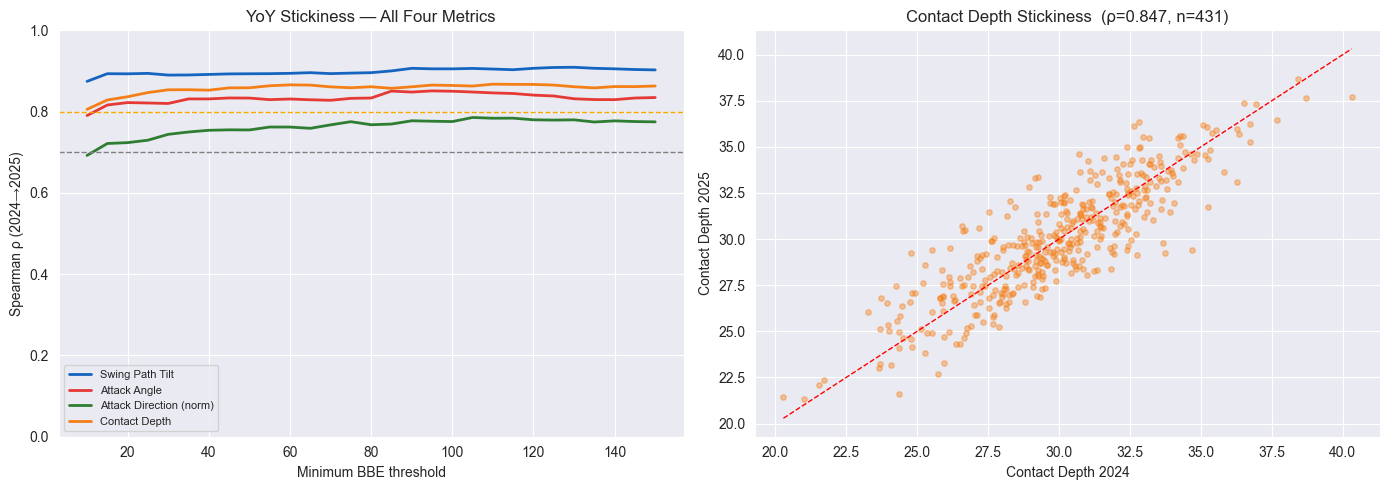

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for (col, label), color in zip(METRICS.items(), COLORS):
    if col not in stick_dfs:
        continue
    s = stick_dfs[col]
    axes[0].plot(s["min_bbe"], s["rho"], color=color, linewidth=2, label=label)

axes[0].axhline(0.70, color="gray",   linewidth=1, linestyle="--")
axes[0].axhline(0.80, color="orange", linewidth=1, linestyle="--")
axes[0].set_xlabel("Minimum BBE threshold")
axes[0].set_ylabel("Spearman ρ (2024→2025)")
axes[0].set_title("YoY Stickiness — All Four Metrics")
axes[0].legend(fontsize=8)
axes[0].set_ylim(0, 1)

# Scatter at MIN_BBE for contact depth (least obvious metric)
cd_col = "intercept_ball_minus_batter_pos_y_inches"
if cd_col in stick_dfs:
    s24 = batter_season_means(ip_2024, cd_col, MIN_BBE)
    s25 = batter_season_means(ip_2025, cd_col, MIN_BBE)
    paired = s24.rename("y2024").to_frame().join(s25.rename("y2025"), how="inner")
    rho_plot, _ = spearmanr(paired["y2024"], paired["y2025"])
    axes[1].scatter(paired["y2024"], paired["y2025"],
                    alpha=0.4, s=15, color="#F57F17")
    lims = [paired.min().min(), paired.max().max()]
    axes[1].plot(lims, lims, "r--", linewidth=1)
    axes[1].set_xlabel("Contact Depth 2024")
    axes[1].set_ylabel("Contact Depth 2025")
    axes[1].set_title(f"Contact Depth Stickiness  (ρ={rho_plot:.3f}, n={len(paired)})")

plt.tight_layout()
plt.show()


## 6. Pairwise Correlations Between Metrics

Qualified batters: 686


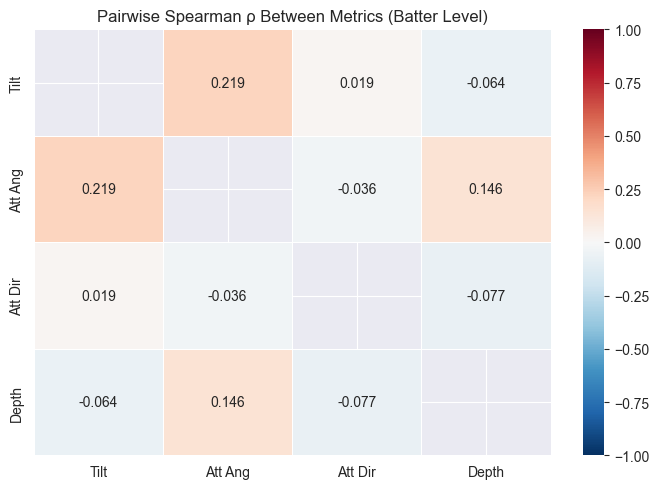


Pairwise Spearman ρ:
          Tilt  Att Ang  Att Dir  Depth
Tilt     1.000    0.219    0.019 -0.064
Att Ang  0.219    1.000   -0.036  0.146
Att Dir  0.019   -0.036    1.000 -0.077
Depth   -0.064    0.146   -0.077  1.000


In [22]:
# Batter-level aggregation — foundation for sections 6–9
batter_agg = (
    ip_all.groupby("batter")
    .agg(
        n                = ("launch_speed",      "count"),
        mean_tilt        = ("swing_path_tilt",   "mean"),
        mean_aa          = ("attack_angle",       "mean"),
        mean_dir         = ("attack_direction_norm", "mean"),
        mean_depth       = ("intercept_ball_minus_batter_pos_y_inches", "mean"),
        sweet_spot_pct   = ("sweet_spot",         "mean"),
        barrel_pct       = ("barrel_adj",         "mean"),
        gb_pct           = ("ground_ball",        "mean"),
        fb_pct           = ("fly_ball",           "mean"),
        pull_pct         = ("pull_flag",          "mean"),
        pull_air_pct     = ("pull_air",           "mean"),
        mean_la          = ("launch_angle",       "mean"),
        mean_ev          = ("launch_speed",       "mean"),
        stand            = ("stand",              "first"),
        pull_given_air   = ("pull_given_air", "mean"), # Pull% among air balls only
    )
    .query(f"n >= {MIN_BBE}")
    .reset_index()
)

print(f"Qualified batters: {len(batter_agg)}")

# Pairwise Spearman matrix
metric_agg_cols = {
    "Tilt":    "mean_tilt",
    "Att Ang": "mean_aa",
    "Att Dir": "mean_dir",
    "Depth":   "mean_depth",
}

n_met  = len(metric_agg_cols)
labels = list(metric_agg_cols.keys())
cols   = list(metric_agg_cols.values())

rho_mat = np.full((n_met, n_met), np.nan)
for i, c1 in enumerate(cols):
    for j, c2 in enumerate(cols):
        paired = batter_agg[[c1, c2]].dropna()
        if len(paired) > 10:
            rho, _ = spearmanr(paired[c1], paired[c2])
            rho_mat[i, j] = float(np.asarray(rho).flat[0])

rho_df = pd.DataFrame(rho_mat, index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(7, 5))
mask = np.eye(n_met, dtype=bool)
sns.heatmap(rho_df, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, linecolor="white",
            mask=mask, ax=ax)
ax.set_title("Pairwise Spearman ρ Between Metrics (Batter Level)")
plt.tight_layout()
plt.show()

print("\nPairwise Spearman ρ:")
print(rho_df.round(4).to_string())


## 7. Outcome Correlations — All Four Metrics

Outcome              Tilt   Att Ang   Att Dir     Depth
-------------------------------------------------------
Sweet Spot%        0.3940    0.2153   -0.0506    0.0199
Barrel%            0.0713    0.2952    0.0333    0.0959
Ground Ball%      -0.1952   -0.4720    0.0837   -0.2413
Fly Ball%          0.0304    0.4408   -0.1018    0.2597
Pull%              0.1301   -0.3975    0.1047   -0.2135
Pull Air%          0.3053    0.0685    0.0027   -0.0118
Mean LA            0.1079    0.4684   -0.1217    0.2719
Mean EV           -0.0378    0.2118   -0.0182    0.1133
GB%               -0.1952   -0.4720    0.0837   -0.2413
Pull% (Air Only)    0.1435   -0.3498    0.0852   -0.2236


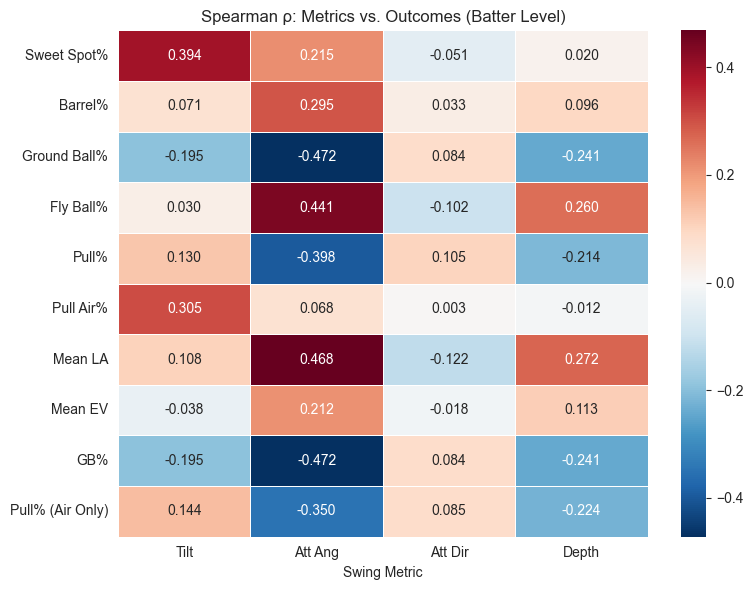

In [24]:
outcome_agg_cols = {
    "Sweet Spot%":  "sweet_spot_pct",
    "Barrel%":      "barrel_pct",
    "Ground Ball%": "gb_pct",
    "Fly Ball%":    "fb_pct",
    "Pull%":        "pull_pct",
    "Pull Air%":    "pull_air_pct",
    "Mean LA":      "mean_la",
    "Mean EV":      "mean_ev",
    "GB%":              "gb_pct",
    "Pull% (Air Only)": "pull_given_air",
}

# Correlation table
header = f"{'Outcome':<15}" + "".join(f"  {l:>8}" for l in labels)
print(header)
print("-" * (15 + 10 * n_met))

corr_data = {}
for out_label, out_col in outcome_agg_cols.items():
    row_rhos = []
    for met_col in cols:
        paired = batter_agg[[met_col, out_col]].dropna()
        rho    = spearmanr(paired[met_col], paired[out_col])[0] if len(paired) > 10 else np.nan
        row_rhos.append(rho)
    corr_data[out_label] = row_rhos
    vals = "".join(f"  {v:>8.4f}" for v in row_rhos)
    print(f"{out_label:<15}{vals}")

# Heatmap
corr_df = pd.DataFrame(corr_data, index=labels).T
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Spearman ρ: Metrics vs. Outcomes (Batter Level)")
ax.set_xlabel("Swing Metric")
plt.tight_layout()
plt.show()


## 8. Ridge Regression With Interactions

In [25]:
def build_features(df, met_cols):
    """
    Build feature matrix: main effects + all pairwise interactions + quadratics.
    """
    sub    = df[met_cols].dropna()
    values = {c: sub[c].values for c in met_cols}
    parts  = {}

    # Main effects
    for c in met_cols:
        parts[c] = values[c]

    # Pairwise interactions
    met_list = list(met_cols)
    for i in range(len(met_list)):
        for j in range(i + 1, len(met_list)):
            key = f"{met_list[i]}×{met_list[j]}"
            parts[key] = values[met_list[i]] * values[met_list[j]]

    # Quadratic terms
    for c in met_list:
        parts[f"{c}²"] = values[c] ** 2

    X        = np.column_stack(list(parts.values()))
    feat_names = list(parts.keys())
    return X, feat_names, sub.index

met_agg_cols = list(metric_agg_cols.values())  # [mean_tilt, mean_aa, mean_dir, mean_depth]
met_short    = ["T", "AA", "D", "CD"]          # short names for display

def run_regression(outcome_col):
    sub  = batter_agg[met_agg_cols + [outcome_col]].dropna()
    T    = sub["mean_tilt"].values
    AA   = sub["mean_aa"].values
    D    = sub["mean_dir"].values
    CD   = sub["mean_depth"].values
    y    = sub[outcome_col].values

    # Main + pairwise interactions + quadratics
    X = np.column_stack([
        T, AA, D, CD,
        T*AA, T*D, T*CD, AA*D, AA*CD, D*CD,
        T**2, AA**2, D**2, CD**2,
    ])
    feat_names = [
        "Tilt", "Att Ang", "Att Dir", "Depth",
        "T×AA", "T×D", "T×CD", "AA×D", "AA×CD", "D×CD",
        "T²", "AA²", "D²", "CD²",
    ]

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge",  RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)),
    ])
    pipe.fit(X, y)
    cv_r2 = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()

    return {
        "cv_r2": round(cv_r2, 4),
        "alpha": round(pipe.named_steps["ridge"].alpha_, 3),
        **dict(zip(feat_names, [round(c, 4) for c in pipe.named_steps["ridge"].coef_])),
    }, pipe, feat_names, X, y

reg_rows  = []
reg_pipes = {}
for out_label, out_col in outcome_agg_cols.items():
    result, pipe, feat_names, X, y = run_regression(out_col)
    result["outcome"] = out_label
    reg_rows.append(result)
    reg_pipes[out_label] = (pipe, feat_names, X, y)

reg_df = pd.DataFrame(reg_rows).set_index("outcome")
print("Ridge Regression — Standardised Coefficients + 5-fold CV R²")
print(reg_df[["cv_r2"] + feat_names].to_string())


Ridge Regression — Standardised Coefficients + 5-fold CV R²
                  cv_r2   Tilt  Att Ang  Att Dir  Depth   T×AA    T×D   T×CD   AA×D  AA×CD   D×CD     T²    AA²     D²    CD²
outcome                                                                                                                      
Sweet Spot%       0.155  0.004    0.011    0.006  0.002  0.012 -0.015 -0.004  0.004 -0.002  0.003  0.014 -0.015 -0.005  0.002
Barrel%           0.040 -0.000    0.016    0.003  0.008 -0.005 -0.002 -0.012  0.002 -0.006 -0.002  0.011 -0.001 -0.001  0.002
Ground Ball%      0.271 -0.002   -0.011    0.001 -0.005 -0.009  0.000 -0.005  0.002 -0.010  0.004 -0.002 -0.003  0.006 -0.004
Fly Ball%         0.217 -0.002    0.009   -0.001  0.006  0.005  0.002  0.003 -0.003  0.009 -0.004 -0.003  0.006 -0.002  0.004
Pull%             0.236  0.006   -0.009    0.003 -0.004 -0.004  0.001  0.003  0.002 -0.007  0.002  0.005 -0.008  0.003 -0.004
Pull Air%         0.065  0.005    0.001    0.000 -0.000  0

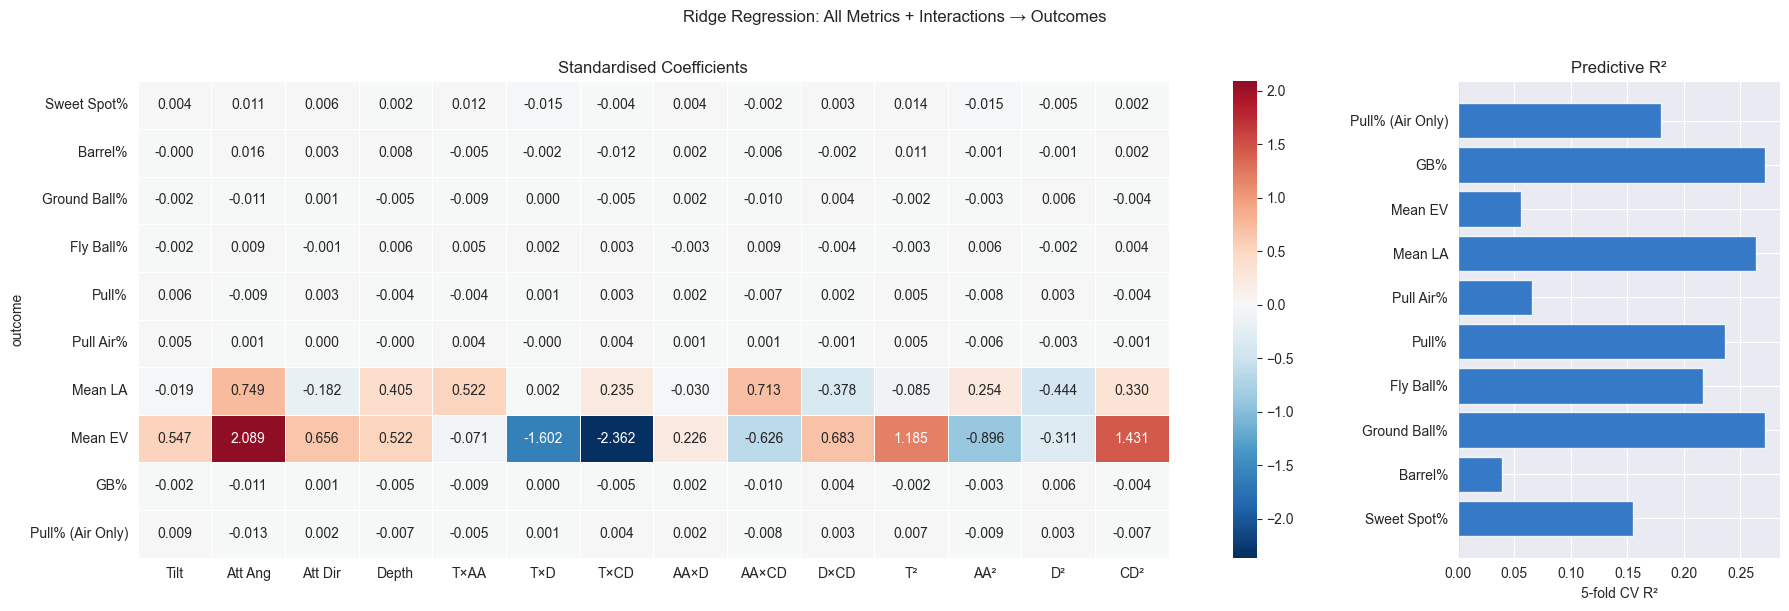

In [26]:
# ── Coefficient heatmap + CV R² ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6),
                          gridspec_kw={"width_ratios": [4, 1]})

sns.heatmap(
    reg_df[feat_names],
    annot=True, fmt=".3f",
    cmap="RdBu_r", center=0,
    linewidths=0.5, linecolor="white",
    ax=axes[0],
)
axes[0].set_title("Standardised Coefficients")
axes[0].set_xlabel("")

r2_vals = reg_df["cv_r2"]
colors  = ["#1565C0" if v > 0 else "#E53935" for v in r2_vals]
axes[1].barh(r2_vals.index, r2_vals.values, color=colors, alpha=0.85)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("5-fold CV R²")
axes[1].set_title("Predictive R²")

plt.suptitle("Ridge Regression: All Metrics + Interactions → Outcomes",
             y=1.01, fontsize=12)
plt.tight_layout()
plt.show()


## 9. Pull Air% Deep Dive — Partial Effects
Holds three metrics at their mean and varies the fourth across its observed range.


Pull Air% model CV R² = 0.0652


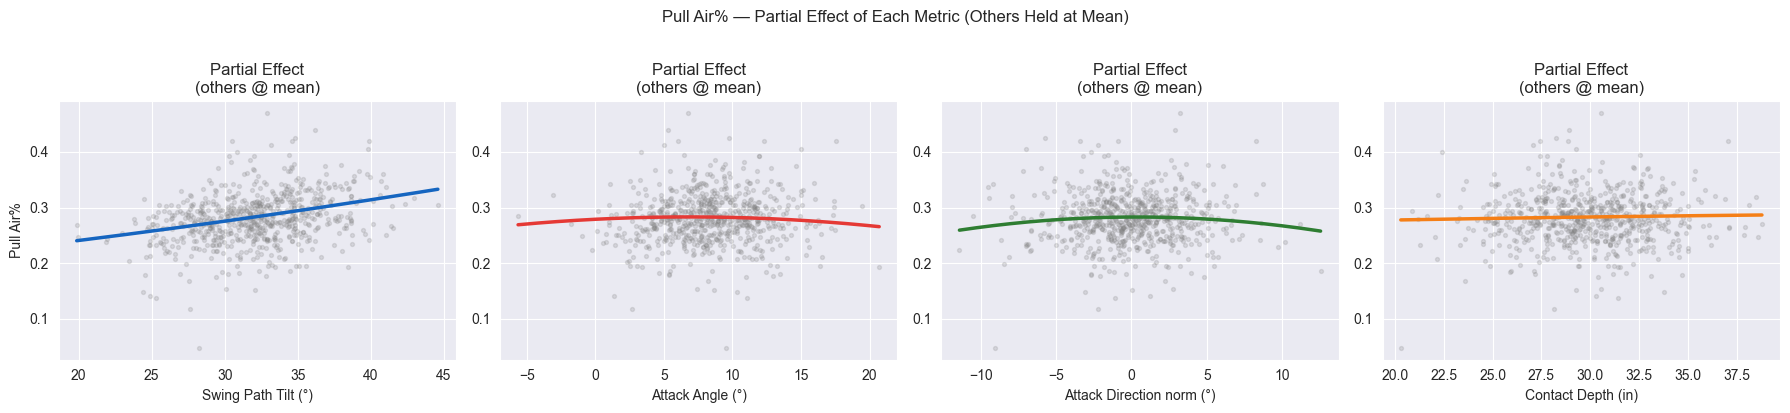

In [27]:
TARGET_OUTCOME = "Pull Air%"
target_col     = outcome_agg_cols[TARGET_OUTCOME]

sub = batter_agg[met_agg_cols + [target_col]].dropna()
T   = sub["mean_tilt"].values
AA  = sub["mean_aa"].values
D   = sub["mean_dir"].values
CD  = sub["mean_depth"].values
y   = sub[target_col].values

t_mean  = T.mean();  t_std  = T.std()
aa_mean = AA.mean(); aa_std = AA.std()
d_mean  = D.mean();  d_std  = D.std()
cd_mean = CD.mean(); cd_std = CD.std()

X_full = np.column_stack([
    T, AA, D, CD,
    T*AA, T*D, T*CD, AA*D, AA*CD, D*CD,
    T**2, AA**2, D**2, CD**2,
])
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge",  RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)),
])
pipe.fit(X_full, y)
cv_r2 = cross_val_score(pipe, X_full, y, cv=5, scoring="r2").mean()
print(f"Pull Air% model CV R² = {cv_r2:.4f}")

def make_X(vary_col, grid, means):
    """Build X holding all metrics at means except vary_col."""
    t_v  = grid if vary_col == "T"  else np.full_like(grid, means["T"])
    aa_v = grid if vary_col == "AA" else np.full_like(grid, means["AA"])
    d_v  = grid if vary_col == "D"  else np.full_like(grid, means["D"])
    cd_v = grid if vary_col == "CD" else np.full_like(grid, means["CD"])
    return np.column_stack([
        t_v, aa_v, d_v, cd_v,
        t_v*aa_v, t_v*d_v, t_v*cd_v, aa_v*d_v, aa_v*cd_v, d_v*cd_v,
        t_v**2, aa_v**2, d_v**2, cd_v**2,
    ])

means = {"T": t_mean, "AA": aa_mean, "D": d_mean, "CD": cd_mean}
raw_vals = {"T": T, "AA": AA, "D": D, "CD": CD}
grids = {k: np.linspace(v.min(), v.max(), 150) for k, v in raw_vals.items()}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
full_labels = {
    "T":  "Swing Path Tilt (°)",
    "AA": "Attack Angle (°)",
    "D":  "Attack Direction norm (°)",
    "CD": "Contact Depth (in)",
}

for ax, (key, color) in zip(axes, zip(["T","AA","D","CD"], COLORS)):
    X_vary = make_X(key, grids[key], means)
    y_pred = pipe.predict(X_vary)

    ax.scatter(raw_vals[key], y, alpha=0.2, s=8, color="gray")
    ax.plot(grids[key], y_pred, color=color, linewidth=2.5)
    ax.set_xlabel(full_labels[key])
    ax.set_ylabel("Pull Air%" if key == "T" else "")
    ax.set_title(f"Partial Effect\n(others @ mean)")

plt.suptitle("Pull Air% — Partial Effect of Each Metric (Others Held at Mean)",
             y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


In [29]:
# ── 2D interaction surface: two most predictive metrics for Pull Air% ─────────
# Find the two metrics with highest |coef| for Pull Air%
pull_air_coefs = reg_df.loc[TARGET_OUTCOME, feat_names]
top2_feats = pull_air_coefs.abs().nlargest(2).index.tolist()
print(f"Top 2 features for {TARGET_OUTCOME}: {top2_feats}")

# Map feature names back to raw arrays
feat_to_arr = {
    "Tilt": T, "Att Ang": AA, "Att Dir": D, "Depth": CD,
}
# Build grid for the two main-effect metrics that appear most
main_top2 = [f for f in top2_feats if f in feat_to_arr][:2]
if len(main_top2) == 2:
    arr1 = feat_to_arr[main_top2[0]]
    arr2 = feat_to_arr[main_top2[1]]
    g1   = np.linspace(arr1.min(), arr1.max(), 60)
    g2   = np.linspace(arr2.min(), arr2.max(), 60)
    G1, G2 = np.meshgrid(g1, g2)

    key_map = {"Tilt": "T", "Att Ang": "AA", "Att Dir": "D", "Depth": "CD"}
    k1, k2  = key_map[main_top2[0]], key_map[main_top2[1]]

    m2 = dict(means)
    rows_grid = []
    for v1, v2 in zip(G1.ravel(), G2.ravel()):
        m2[k1] = v1; m2[k2] = v2
        rows_grid.append([m2["T"], m2["AA"], m2["D"], m2["CD"],
                          m2["T"]*m2["AA"], m2["T"]*m2["D"], m2["T"]*m2["CD"],
                          m2["AA"]*m2["D"], m2["AA"]*m2["CD"], m2["D"]*m2["CD"],
                          m2["T"]**2, m2["AA"]**2, m2["D"]**2, m2["CD"]**2])

    Z = pipe.predict(np.array(rows_grid)).reshape(G1.shape)

    fig, ax = plt.subplots(figsize=(8, 6))
    c = ax.contourf(G1, G2, Z, levels=20, cmap="RdYlBu_r")
    plt.colorbar(c, ax=ax, label="Predicted Pull Air%")
    ax.set_xlabel(main_top2[0])
    ax.set_ylabel(main_top2[1])
    ax.set_title(f"Pull Air% Surface: {main_top2[0]} × {main_top2[1]}")
    plt.tight_layout()
    plt.show()
else:
    print("Top features are interaction terms — skipping 2D surface plot.")


Top 2 features for Pull Air%: ['AA²', 'Tilt']
Top features are interaction terms — skipping 2D surface plot.


 min_bbe    n_paired       rho
      10         454    0.5027
      15         433    0.5416
      20         406    0.5686
      25         389    0.5778
      30         377    0.5749
      35         365    0.5953
      40         352    0.6009
      45         335    0.6033
      50         321    0.6238
      55         309    0.6137
      60         295    0.6178
      65         280    0.6318
      70         273    0.6303
      75         265    0.6334
      80         251    0.6398
      85         247    0.6404
      90         235    0.6309
      95         227    0.6335
     100         215    0.6488
     105         209    0.6405
     110         202    0.6368
     115         198    0.6452
     120         195    0.6446
     125         189    0.6392
     130         178    0.6455
     135         175    0.6659
     140         167    0.6714
     145         161    0.6637
     150         152    0.6567


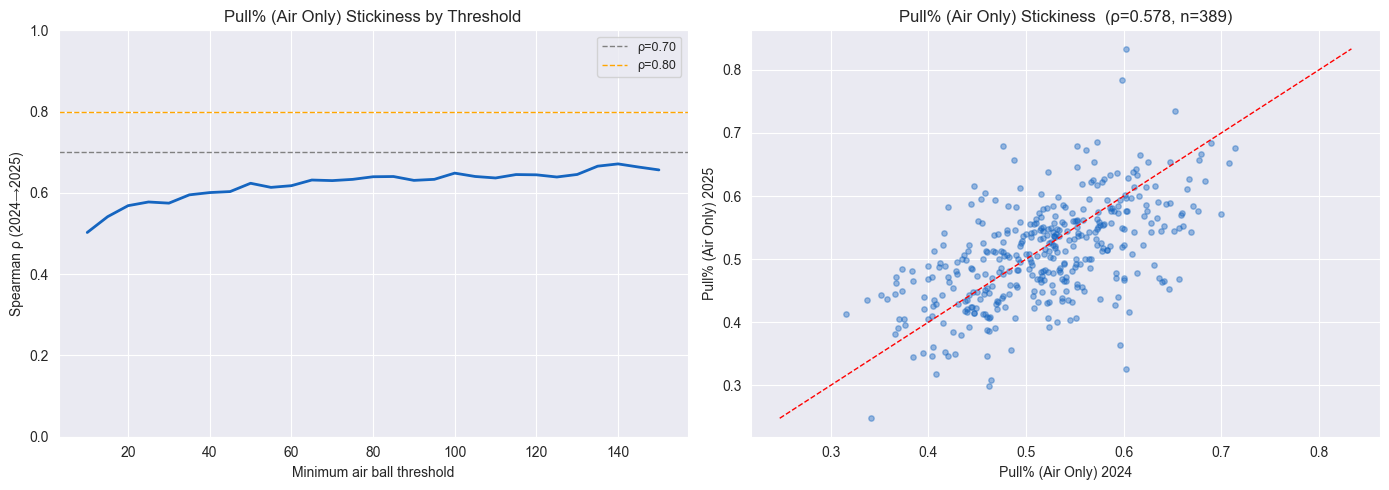

In [28]:
# ── Stickiness of Pull% (Air Only) ───────────────────────────────────────────
print(f"{'min_bbe':>8}  {'n_paired':>10}  {'rho':>8}")
pull_air_only_stick = []

for min_bbe in range(10, 155, 5):
    # Only count air ball events toward the BBE threshold
    pa24 = (
        ip_2024[ip_2024["air_ball"] == 1]
        .groupby("batter")["pull_given_air"]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")["mean"]
    )
    pa25 = (
        ip_2025[ip_2025["air_ball"] == 1]
        .groupby("batter")["pull_given_air"]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")["mean"]
    )
    paired = pa24.rename("y2024").to_frame().join(pa25.rename("y2025"), how="inner")
    if len(paired) < 20:
        continue
    rho, _ = spearmanr(paired["y2024"], paired["y2025"])
    pull_air_only_stick.append({"min_bbe": min_bbe, "n_paired": len(paired), "rho": rho})
    print(f"{min_bbe:>8}  {len(paired):>10}  {rho:>8.4f}")

pa_only_stick = pd.DataFrame(pull_air_only_stick)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(pa_only_stick["min_bbe"], pa_only_stick["rho"],
             color="#1565C0", linewidth=2)
axes[0].axhline(0.70, color="gray",   linewidth=1, linestyle="--", label="ρ=0.70")
axes[0].axhline(0.80, color="orange", linewidth=1, linestyle="--", label="ρ=0.80")
axes[0].set_xlabel("Minimum air ball threshold")
axes[0].set_ylabel("Spearman ρ (2024→2025)")
axes[0].set_title("Pull% (Air Only) Stickiness by Threshold")
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1)

pa24_plot = (
    ip_2024[ip_2024["air_ball"] == 1]
    .groupby("batter")["pull_given_air"]
    .agg(n="count", mean="mean")
    .query(f"n >= {MIN_BBE}")["mean"]
)
pa25_plot = (
    ip_2025[ip_2025["air_ball"] == 1]
    .groupby("batter")["pull_given_air"]
    .agg(n="count", mean="mean")
    .query(f"n >= {MIN_BBE}")["mean"]
)
paired_plot = pa24_plot.rename("y2024").to_frame().join(pa25_plot.rename("y2025"), how="inner")
rho_plot, _ = spearmanr(paired_plot["y2024"], paired_plot["y2025"])

axes[1].scatter(paired_plot["y2024"], paired_plot["y2025"],
                alpha=0.4, s=15, color="#1565C0")
lims = [paired_plot.min().min(), paired_plot.max().max()]
axes[1].plot(lims, lims, "r--", linewidth=1)
axes[1].set_xlabel("Pull% (Air Only) 2024")
axes[1].set_ylabel("Pull% (Air Only) 2025")
axes[1].set_title(f"Pull% (Air Only) Stickiness  (ρ={rho_plot:.3f}, n={len(paired_plot)})")

plt.tight_layout()
plt.show()